# Earnings analysis with all observations

This notebook keeps every row in `stats.sav`. `B24_B25_Net_earnings` is an interval-code variable. If a separate continuous wage column becomes available, set `DIRECT_WAGE_COLUMN` below and it will be classified into the same bins.

In [1]:
import numpy as np
import pandas as pd
import pyreadstat
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
DATA_PATH = 'stats.sav'
CATEGORY_COLUMN = 'B24_B25_Net_earnings'
WEIGHT_COLUMN = 'P_Weights'
DIRECT_WAGE_COLUMN = None
WAGE_BIN_EDGES = [-np.inf, 100, 150, 200, 300, 400, 500, 600, 800, 1000, 1500, 2000, np.inf]
WAGE_BIN_LABELS = list(range(1, 13))

In [3]:
df, metadata = pyreadstat.read_sav(DATA_PATH, apply_value_formats=False)
required_columns = [CATEGORY_COLUMN, WEIGHT_COLUMN]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise KeyError(f'Missing required columns: {missing_columns}')
print(f'Rows loaded: {len(df):,}')
print(f'Columns loaded: {len(df.columns):,}')
display(df[[CATEGORY_COLUMN, WEIGHT_COLUMN]].describe(include='all').T)

Rows loaded: 58,170
Columns loaded: 130


,count,mean,std,min,25%,50%,75%,max
B24_B25_Net_earnings,13823.0,8.182305,2.361710,1.000000,7.000000,9.000000,10.000000,12.000000
P_Weights,58170.0,203.749965,158.838129,12.495379,107.504159,158.940352,235.547458,3342.857963


In [4]:
value_labels = metadata.variable_value_labels.get(CATEGORY_COLUMN, {})
display(pd.DataFrame({'original_code': list(value_labels.keys()), 'SPSS_label': list(value_labels.values())}))
print('Original category frequencies, including missing values:')
display(df[CATEGORY_COLUMN].value_counts(dropna=False).sort_index())

,original_code,SPSS_label
0,0.0,არ აუღია ხელფასი ბოლო ნამუშევარ თვეში
1,1.0,100 ლარი ან ნაკლები
2,2.0,101-150 ლარი
3,3.0,151-200 ლარი
4,4.0,201-300 ლარი
5,5.0,301-400 ლარი
6,6.0,401-500 ლარი
7,7.0,501-600 ლარი
8,8.0,601-800 ლარი
9,9.0,801-1000 ლარი


Original category frequencies, including missing values:


B24_B25_Net_earnings
1.0        57
2.0        65
3.0       177
4.0      1293
5.0       721
6.0      1008
7.0      1065
8.0      2302
9.0      2169
10.0     3029
11.0     1365
12.0      572
NaN     44347
Name: count, dtype: int64

In [5]:
def classify_direct_wages(wages):
    numeric_wages = pd.to_numeric(wages, errors='coerce')
    return pd.cut(numeric_wages, bins=WAGE_BIN_EDGES, labels=WAGE_BIN_LABELS, include_lowest=True, right=True).astype('Int64')

analysis_df = df.copy()
analysis_df['wage_bin'] = pd.Series(pd.NA, index=analysis_df.index, dtype='Int64')
analysis_df['wage_source'] = 'unavailable'
category_codes = pd.to_numeric(analysis_df[CATEGORY_COLUMN], errors='coerce')
category_mask = category_codes.between(1, 12, inclusive='both')
analysis_df.loc[category_mask, 'wage_bin'] = category_codes.loc[category_mask].astype('Int64')
analysis_df.loc[category_mask, 'wage_source'] = 'SPSS interval code'
if DIRECT_WAGE_COLUMN is not None:
    if DIRECT_WAGE_COLUMN not in analysis_df.columns:
        raise KeyError(f'DIRECT_WAGE_COLUMN not found: {DIRECT_WAGE_COLUMN}')
    direct_bins = classify_direct_wages(analysis_df[DIRECT_WAGE_COLUMN])
    direct_mask = direct_bins.notna() & ~category_mask
    analysis_df.loc[direct_mask, 'wage_bin'] = direct_bins.loc[direct_mask]
    analysis_df.loc[direct_mask, 'wage_source'] = 'direct numeric wage'
analysis_df.loc[category_codes.eq(0), 'wage_source'] = 'no wage reported'
analysis_df.loc[category_codes.eq(88), 'wage_source'] = 'refused'
print(f'Rows retained: {len(analysis_df):,}')
display(analysis_df['wage_source'].value_counts(dropna=False))

Rows retained: 58,170


wage_source
unavailable           44347
SPSS interval code    13823
Name: count, dtype: int64

In [6]:
row_summary = (analysis_df.groupby(['wage_bin', 'wage_source'], dropna=False, as_index=False).agg(unweighted_count=(WEIGHT_COLUMN, 'size'), weighted_count=(WEIGHT_COLUMN, 'sum')).sort_values(['wage_bin', 'wage_source'], na_position='last').reset_index(drop=True))
row_summary['share_of_all_rows'] = row_summary['unweighted_count'] / len(analysis_df)
row_summary['share_of_all_weight'] = row_summary['weighted_count'] / analysis_df[WEIGHT_COLUMN].sum()
display(row_summary)
classified_mask = analysis_df['wage_bin'].notna()
print(f'Classified wage rows: {classified_mask.sum():,}')
print(f'Rows without a wage bin: {(~classified_mask).sum():,}')
print('No rows were removed from analysis_df.')

,wage_bin,wage_source,unweighted_count,weighted_count,share_of_all_rows,share_of_all_weight
0,1,SPSS interval code,57,9.007170e+03,0.000980,0.000760
1,2,SPSS interval code,65,1.037718e+04,0.001117,0.000876
2,3,SPSS interval code,177,2.337052e+04,0.003043,0.001972
3,4,SPSS interval code,1293,1.722131e+05,0.022228,0.014530
4,5,SPSS interval code,721,1.175515e+05,0.012395,0.009918
5,6,SPSS interval code,1008,1.707440e+05,0.017329,0.014406
6,7,SPSS interval code,1065,2.012559e+05,0.018308,0.016981
7,8,SPSS interval code,2302,4.640019e+05,0.039574,0.039149
8,9,SPSS interval code,2169,4.446433e+05,0.037287,0.037516
9,10,SPSS interval code,3029,6.183102e+05,0.052072,0.052169


Classified wage rows: 13,823
Rows without a wage bin: 44,347
No rows were removed from analysis_df.


In [7]:
classified = analysis_df.loc[classified_mask, ['wage_bin', WEIGHT_COLUMN]].copy()
if classified.empty:
    raise ValueError('There are no classified wages to summarize.')
bin_stats = (classified.groupby('wage_bin', as_index=False).agg(weighted_count=(WEIGHT_COLUMN, 'sum'), unweighted_count=(WEIGHT_COLUMN, 'size')).sort_values('wage_bin'))
bin_stats['share_of_classified_weight'] = bin_stats['weighted_count'] / bin_stats['weighted_count'].sum()
bin_stats['cumulative_share'] = bin_stats['share_of_classified_weight'].cumsum()
display(bin_stats)
weighted_mean_bin = np.average(classified['wage_bin'], weights=classified[WEIGHT_COLUMN])
sorted_classified = classified.sort_values('wage_bin')
cumulative_weights = sorted_classified[WEIGHT_COLUMN].cumsum()
weighted_median_bin = sorted_classified.loc[cumulative_weights >= cumulative_weights.iloc[-1] / 2, 'wage_bin'].iloc[0]
print(f'Weighted mean bin: {weighted_mean_bin:.4f}')
print(f'Weighted median bin: {weighted_median_bin}')

,wage_bin,weighted_count,unweighted_count,share_of_classified_weight,cumulative_share
0,1,9007.170351,57,0.003412,0.003412
1,2,10377.177848,65,0.003931,0.007344
2,3,23370.519074,177,0.008854,0.016198
3,4,172213.098024,1293,0.065243,0.081440
4,5,117551.458354,721,0.044534,0.125974
5,6,170743.999202,1008,0.064686,0.190660
6,7,201255.889717,1065,0.076245,0.266906
7,8,464001.885829,2302,0.175786,0.442692
8,9,444643.328587,2169,0.168452,0.611144
9,10,618310.196370,3029,0.234245,0.845389


Weighted mean bin: 8.4557
Weighted median bin: 9


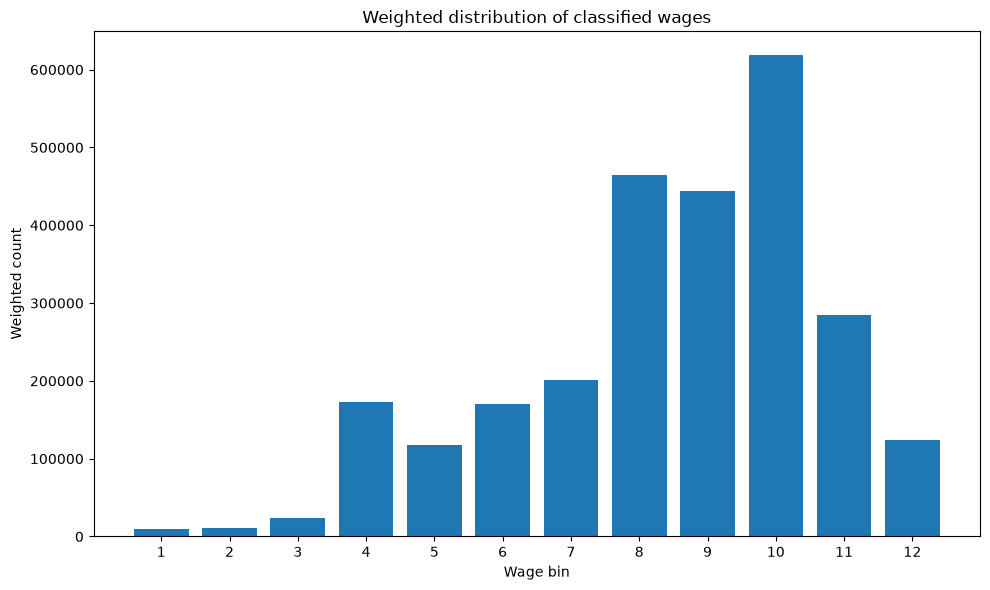

In [8]:
plt.figure(figsize=(10, 6))
plt.bar(bin_stats['wage_bin'].astype(str), bin_stats['weighted_count'])
plt.xlabel('Wage bin')
plt.ylabel('Weighted count')
plt.title('Weighted distribution of classified wages')
plt.tight_layout()
plt.show()

In [9]:
analysis_df.to_csv('earnings_all_rows.csv', index=False)
row_summary.to_csv('earnings_row_summary.csv', index=False)
bin_stats.to_csv('earnings_classified_bin_summary.csv', index=False)
print('Wrote all-row and summary CSV files.')

Wrote all-row and summary CSV files.
